## My Question:
### Whats the probablity of rolling a even number on a normal 6 sided dice?

## My Study:
### My random process in my study is rolling a six sided dice. One trial counts as rolling the six sided dice their will be six outcomes 1,2,3,4,5,6. Since we are only caring about three outcomes which are the evens in our outcomes 2,4,6 they are our event.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [2]:
# 1. Setup simulation parameters
rng = np.random.default_rng(seed=42)
num_rolls = 1000
rolls = rng.integers(1, 7, size=num_rolls)

# 2. Build DataFrame with cumulative tracking
df = pd.DataFrame({"roll_number": np.arange(1, num_rolls + 1), "outcome": rolls})
df["is_even"] = df["outcome"].isin([2, 4, 6])
df["evens_so_far"] = df["is_even"].cumsum()
df["relative_freq_so_far"] = df["evens_so_far"] / df["roll_number"]

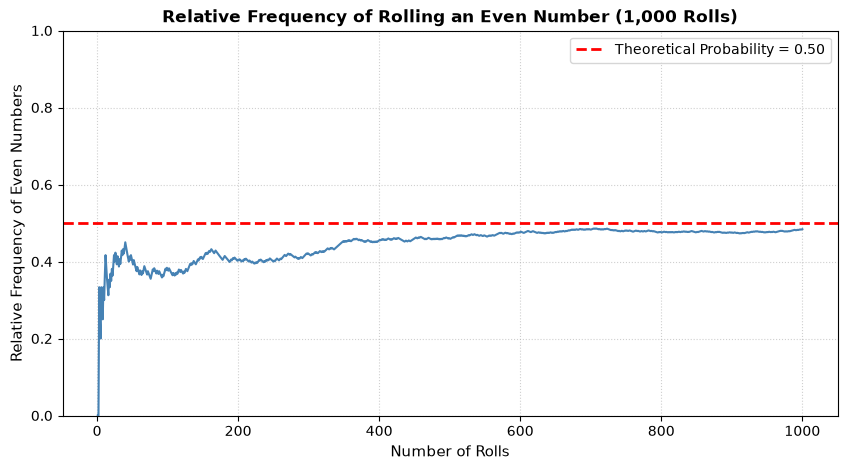

In [5]:
# 3. Create the plot
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df, x="roll_number", y="relative_freq_so_far", color="steelblue", linewidth=1.5
)
# Add the theoretical probability line (0.50)
plt.axhline(
    0.50,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Theoretical Probability = 0.50",
)

# Customize graph aesthetics
plt.title(
    "Relative Frequency of Rolling an Even Number (1,000 Rolls)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Number of Rolls", fontsize=11)
plt.ylabel("Relative Frequency of Even Numbers", fontsize=11)
plt.ylim(0, 1)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10)

# Display graph in notebook
plt.show()

In [6]:
df = pd.DataFrame({"roll_number": np.arange(1, num_rolls + 1), "outcome": rolls})
df["is_even"] = df["outcome"].isin([2, 4, 6])

# 2. Define milestone sample sizes to evaluate
milestones = [10, 25, 50, 100, 250, 500, 750, 1000]
table_data = []

# 3. Calculate running stats at each milestone
for n in milestones:
    sub_sample = df.iloc[:n]
    even_count = sub_sample["is_even"].sum()
    rel_freq = even_count / n
    distance = abs(rel_freq - 0.50)
    
    table_data.append({
        "Rolls (n)": n,
        "Even Count": even_count,
        "Relative Frequency": round(rel_freq, 4),
        "Distance from 0.50": round(distance, 4)
    })

# 4. Display the formatted DataFrame table
milestone_table = pd.DataFrame(table_data)
milestone_table

,Rolls (n),Even Count,Relative Frequency,Distance from 0.50
0,10,3,0.300,0.200
1,25,10,0.400,0.100
2,50,20,0.400,0.100
3,100,38,0.380,0.120
4,250,100,0.400,0.100
5,500,230,0.460,0.040
6,750,360,0.480,0.020
7,1000,484,0.484,0.016


## My Conclusion:
### In conclusion our thoretical probablity is .5 that it should land on evens compare to odds on our six sided dice the amount it lands on both should be the same or more rather the chance. But as you can see in the table above seeing the empirical probability of my trials at 10 trials the relative frequency is .3 which is .2 away from our theoretical probablity which is not bad for a start. but as the number of trials increase is when you can see a trend at 100 trials relative frequency is .38 slightly closer to .5 and at 500 trials you can see relative frequency is .46 now its getting more closer to .5 and at 1000 its .484 which is even closer to .5 this shows that over time our empirucal probablitiy starts to match closer and closer to our theoretical probablility.

## My graph:

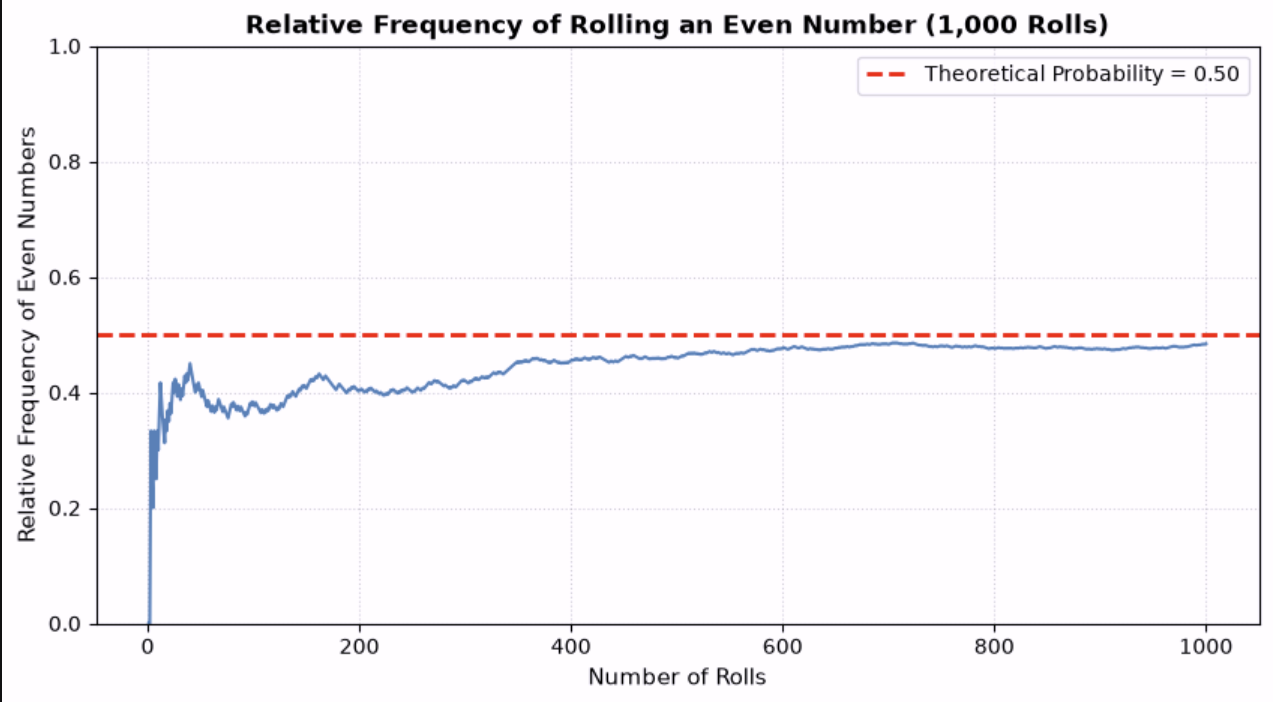

### This graph proves my point by showing each time a side was even in the 1000 of rolls rolling the dice and as you can see over the period of a thousand rolls the frequency of even numbers go up showing how much times it occuered in that number of rolls and as you can see the frequency shoots up but then starts to even out when it gets near our theortical probablity .5 showing that .5 is most likely correct because the chance to land on a odd is the same amount to land on a even.